# Maintenance Shift Optimization (MILP with Pyomo & HiGHS)
Predicting that a machine is going to fail is only half of the problem. In a real factory, if our Machine Learning model warns us that **16 machines** are at risk this week, we cannot repair all 16 on Monday morning: technicians work in **8-hour shifts**, and we cannot stop several machines of the same model at once without blocking production.

In this notebook, we build a **Mixed-Integer Linear Programming (MILP)** model that takes our LightGBM predictions and creates an optimal **Monday-to-Friday shift schedule** for the maintenance team. Finally, we compare our schedule against what actually happened in reality to see how many breakdowns we prevented, how many false alarms we paid for, and how much money we saved.

In [14]:
# Libraries for data handling, database connection, MILP optimization and plotting
import pandas as pd
import numpy as np
import joblib
import pyomo.environ as pyo
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import highspy, pyomo.contrib.appsi.solvers.highs as _hm
_hm.highspy = highspy
_hm.highspy_available = True

In [16]:
# Load total fleet size for each machine model from SQLite
connection = sqlite3.connect('../data/maintenance.db')
fleet_df = pd.read_sql_query("select model, count(*) from machines group by model", connection)
fleet_size = fleet_df.set_index('model').to_dict()['count(*)']

# Load the engineered dataset and our trained LightGBM model
data = pd.read_csv('../data/features.csv')
data['datetime'] = pd.to_datetime(data['datetime'])
data['model'] = data['model'].astype('category')
model = joblib.load('../models/lightgbm_failures.pkl')

## 1. Selecting a Critical Week in the Test Set
Instead of choosing a random week from our test period (October-December), let's find the exact date when the highest number of machines are about to fail at the same time. This allows us to test our scheduling system under real workshop stress.

In [17]:
# Find the timestamps with the highest number of upcoming failures in the test set
data[(data['failure_next_24h'] != 'none') & (data['datetime'] > pd.to_datetime('2015-10-01'))]['failure_next_24h'].groupby(data['datetime']).count().sort_values(ascending=False).head(5)

datetime
2015-11-27 06:00:00    9
2015-10-01 06:00:00    8
2015-10-17 06:00:00    8
2015-12-30 06:00:00    7
2015-12-08 13:00:00    7
Name: failure_next_24h, dtype: int64

The biggest peak in the entire test set happens on **November 27th, 2015 at 06:00**, when **9 machines** are about to break down simultaneously. Let's take that full week (`2015-11-22` to `2015-11-28`) and run our LightGBM model to get the failure probabilities for all machines.

In [18]:
# Filter the test window around the November 27th peak (Nov 22 to Nov 28)
window = data[(data['datetime'] >= '2015-11-22') & (data['datetime'] < '2015-11-28')].copy()
X_win = window.drop(columns=['datetime', 'failure_next_24h', 'machineID'])

# Predict component failure probabilities using our trained LightGBM model
probs = pd.DataFrame(model.predict_proba(X_win), columns=model.classes_, index=X_win.index)
comp_cols = ['comp1', 'comp2', 'comp3', 'comp4']
window['pred_comp'] = probs[comp_cols].idxmax(axis=1)
window['pred_prob'] = probs[comp_cols].max(axis=1)

To build our interactive dashboard in Power BI, we need clean tabular data in .csv format. Since the full 	elemetry.csv file is very large and our optimization focuses on the critical week from November 22 to November 28, we filter only that week's sensor readings and export them to the data/powerbi folder.

In [ ]:
df_telem_november = pd.read_sql_query("select * from telemetry", connection)
df_telem_november['datetime'] = pd.to_datetime(df_telem_november['datetime'])
df_telem_november = df_telem_november[(df_telem_november['datetime'] >= '2015-11-22') & (df_telem_november['datetime'] < '2015-11-28')].copy()

with open('../data/powerbi/pbi_sensor_week.csv', 'w', encoding='utf-8', newline='') as f:
    f.write(df_telem_november.to_csv(index=False))

## 2. Identifying Machine Alerts, Fleet Criticality & Real Outcomes
We collect all machines where our LightGBM model predicts a failure probability of at least **50%** (`pred_prob >= 0.5`). In this week, the model triggers **16 alerts**.

Before scheduling them, we add two key pieces of information:
1. **Fleet Risk by Machine Model (`fleet_risk`):** Not all machine models have the same backup capacity in the factory. For instance, there are only **16 machines of `model1`** in the entire plant, and **5 of them (31.2%)** are in alert this week. By contrast, `model3` has 35 machines and only 3 are in alert (8.6%). Delaying a `model1` repair is therefore much riskier for the plant.
2. **Real Outcome (`outcome` - for final evaluation only):** To evaluate our schedule honestly at the end, we also check `failure_next_24h` to see if each flagged machine was actually going to fail (**Prevented Failure**, 14 machines) or if the model made a mistake (**False Alarm**, 2 machines: `M77` and `M28`). *Note: the optimizer does NOT use this real outcome column when making its decisions—it only sees `pred_prob`.*

In [33]:
# Check the real failure outcome per machine in this window to compare predictions vs. reality
real_per_machine = window.groupby('machineID')['failure_next_24h'].apply(
    lambda s: s[s != 'none'].iloc[0] if (s != 'none').any() else 'none'
).to_dict()

alerts = (
    window[window['pred_prob'] >= 0.5]
    .sort_values(by='pred_prob', ascending=False)
    .groupby('machineID', as_index=False)
    .first()[['machineID', 'model', 'pred_comp', 'pred_prob']]
    .sort_values('pred_prob', ascending=False)
    .reset_index(drop=True)
)
alerts['real_failure'] = alerts['machineID'].map(real_per_machine)
alerts['outcome'] = np.where(alerts['real_failure'] != 'none', 'Prevented Failure', 'False Alarm')

model_alerts_count = alerts['model'].value_counts().to_dict()
alerts['fleet_risk'] = alerts['model'].astype(str).map(lambda m: model_alerts_count[m] / fleet_size[m])
alerts
with open('../data/powerbi/pbi_fleet_summary.csv', 'w', encoding = 'utf-8', newline='') as f:
    f.write(alerts.to_csv(index=False) )

## 3. Workshop Parameters & 8-Hour Shifts (Monday to Friday)
Since the original Kaggle dataset does not include financial costs or repair times, we define realistic workshop estimates for each of the four components:
- **`prev_cost`:** Cost of replacing the component during a planned preventive stop (500-800 EUR).
- **`fail_cost`:** Cost if the component breaks unexpectedly during production (4,400-5,800 EUR, due to line stoppage and urgent repairs).
- **`hours`:** Technician hours required to replace the component (3.0 to 5.0 hours).

We organise the week into **10 standard working shifts of 8 hours each**: Monday to Friday, Morning and Afternoon.

In [8]:
# Estimated preventive cost (EUR), unplanned breakdown cost (EUR), and repair time (hours) per component
comp_param = {
    'comp1': {'prev_cost': 700, 'fail_cost': 5200, 'hours': 4.0},
    'comp2': {'prev_cost': 500, 'fail_cost': 4400, 'hours': 3.0},
    'comp3': {'prev_cost': 800, 'fail_cost': 5800, 'hours': 5.0},
    'comp4': {'prev_cost': 600, 'fail_cost': 4800, 'hours': 4.5}
}

# 10 working shifts of 8 hours each (Monday to Friday, Morning and Afternoon)
shifts = [
    'Mon_morning', 'Mon_afternoon', 'Tue_morning', 'Tue_afternoon', 'Wed_morning', 
    'Wed_afternoon', 'Thu_morning', 'Thu_afternoon', 'Fri_morning', 'Fri_afternoon'
]

## 4. Formulating and Solving the MILP Optimization Model
Now we ask our mathematical model (**Pyomo + HiGHS solver**) to assign each of the 16 flagged machines ($i$) to one of the 10 shifts ($t$) using a binary decision variable $x_{i,t} \in \{0, 1\}$:

- **Objective Function:** Minimize the preventive cost plus the expected risk of delaying a repair to later shifts ($t$), weighted by `fleet_risk` so scarce models like `model1` are repaired as early as possible.
- **Constraint 1 (One shift per machine):** All 16 flagged machines must be scheduled during the week.
- **Constraint 2 (8-Hour Workday Limit):** A technician shift lasts **8 hours**, so the sum of repair hours assigned to any single shift cannot exceed `8.0` hours.
- **Constraint 3 (Max 2 machines per shift):** At most 2 machines can be intervened in the same 8-hour shift.
- **Constraint 4 (Model line protection):** At most **1 machine of the same `model`** can be stopped in the same shift, ensuring we never shut down two machines of the same model at the same time.

In [9]:
m = pyo.ConcreteModel()
m.I = pyo.RangeSet(0, len(alerts) - 1)
m.T = pyo.RangeSet(0, len(shifts) - 1)
m.M = pyo.Set(initialize=alerts['model'].astype(str).unique().tolist())

# Binary decision variable: x[i, t] = 1 if machine i is repaired in shift t
m.x = pyo.Var(m.I, m.T, domain=pyo.Binary)

# Expected cost of assigning machine i to shift t (used by the optimizer before knowing the future)
def cost_matrix(i, t):
    comp = alerts.loc[i, 'pred_comp']
    prob = alerts.loc[i, 'pred_prob']
    f_risk = alerts.loc[i, 'fleet_risk']
    c_prev = comp_param[comp]['prev_cost']
    c_fail = comp_param[comp]['fail_cost']
    delay_risk = prob * (0.06 * t) * (1 + f_risk) * c_fail
    return c_prev + delay_risk

# Objective function: minimize total expected weekly cost
m.obj = pyo.Objective(
    expr=sum(cost_matrix(i, t) * m.x[i, t] for i in m.I for t in m.T),
    sense=pyo.minimize
)

# Constraint 1: Each machine is scheduled in exactly one shift
m.c_one_shift = pyo.Constraint(m.I, rule=lambda m, i: sum(m.x[i, t] for t in m.T) == 1)

# Constraint 2: Maximum capacity of 8 technician hours per shift (standard 8h workday)
m.c_tech_hours = pyo.Constraint(m.T, rule=lambda m, t: sum(comp_param[alerts.loc[i, 'pred_comp']]['hours'] * m.x[i, t] for i in m.I) <= 8.0)

# Constraint 3: Maximum 2 machines repaired per 8-hour shift
m.c_max_machines = pyo.Constraint(m.T, rule=lambda m, t: sum(m.x[i, t] for i in m.I) <= 2)

# Constraint 4: Maximum 1 machine of the same model stopped per shift
m.c_same_model = pyo.Constraint(m.T, m.M, rule=lambda m, t, m_: sum(m.x[i, t] for i in m.I if str(alerts.loc[i, 'model']) == m_) <= 1)

# Solve the MILP with HiGHS
solver = pyo.SolverFactory('appsi_highs')
result = solver.solve(m)

## 5. Auditing the Optimal Schedule Against Reality (Savings vs. False Alarms)
Once the solver finds the optimal schedule, we audit what actually happens in the factory when we follow this plan:
- On the **14 Prevented Failures**, we pay the planned preventive cost (`prev_cost`) and avoid the much larger unplanned breakdown (`real_reactive_cost`), generating huge positive savings.
- On the **2 False Alarms (`M77` and `M28`)**, the machines would not have failed in reality (`real_reactive_cost = 0 EUR`), so replacing their component costs us **`-700 EUR` each (`-1,400 EUR` total)**.
- Even after paying for those 2 false alarms, our net weekly savings reach **+58,100 EUR** with **zero unexpected breakdowns**.

In [32]:
schedule_rows = []

for i in m.I: 
    for t in m.T:
        if pyo.value(m.x[i, t]) > 0.5:
            prob = alerts.loc[i, 'pred_prob']
            comp = alerts.loc[i, 'pred_comp']
            real_f = alerts.loc[i, 'real_failure']
            outcome = alerts.loc[i, 'outcome']
            prev_c = comp_param[comp]['prev_cost']
            real_reactive_c = comp_param[comp]['fail_cost'] if real_f != 'none' else 0.0
            real_savings = real_reactive_c - prev_c
            schedule_rows.append({
                'shift_idx': t,
                'shift': shifts[t],
                'machineID': int(alerts.loc[i, 'machineID']),
                'model': str(alerts.loc[i, 'model']),
                'pred_comp': comp,
                'pred_prob': prob,
                'real_failure': real_f,
                'outcome': outcome,
                'repair_hours': comp_param[comp]['hours'],
                'prev_cost': prev_c,
                'real_reactive_cost': real_reactive_c,
                'real_net_savings': real_savings
            })

df_schedule = pd.DataFrame(schedule_rows).sort_values(['shift_idx', 'model']).reset_index(drop=True)
with open('../reports/schedule.md', 'w', encoding='utf-8') as f:
    f.write(df_schedule.drop(columns=['shift_idx']).to_markdown(index=False))
# for Power BI we need CSV:
with open('../data/powerbi/pbi_schedule.csv', 'w', encoding='utf-8', newline='') as f:
    f.write(df_schedule.to_csv(index=False))

print("Total Preventive Cost Paid (EUR):", df_schedule['prev_cost'].sum())
print("Total Breakdown Cost Avoided (EUR):", df_schedule['real_reactive_cost'].sum())
print("Total Real Net Savings (EUR):", df_schedule['real_net_savings'].sum())
df_schedule.drop(columns=['shift_idx'])

Total Preventive Cost Paid (EUR): 9900
Total Breakdown Cost Avoided (EUR): 68000.0
Total Real Net Savings (EUR): 58100.0


,shift,machineID,model,pred_comp,pred_prob,real_failure,outcome,repair_hours,prev_cost,real_reactive_cost,real_net_savings
0,Mon_morning,24,model1,comp3,0.999998,comp3,Prevented Failure,5.0,800,5800.0,5000.0
1,Mon_morning,29,model4,comp2,0.999999,comp2,Prevented Failure,3.0,500,4400.0,3900.0
2,Mon_afternoon,17,model1,comp2,0.999999,comp2,Prevented Failure,3.0,500,4400.0,3900.0
3,Mon_afternoon,98,model2,comp3,0.999999,comp3,Prevented Failure,5.0,800,5800.0,5000.0
4,Tue_morning,73,model2,comp1,0.999992,comp1,Prevented Failure,4.0,700,5200.0,4500.0
5,Tue_morning,77,model4,comp1,0.999992,none,False Alarm,4.0,700,0.0,-700.0
6,Tue_afternoon,33,model3,comp1,0.999997,comp1,Prevented Failure,4.0,700,5200.0,4500.0
7,Tue_afternoon,28,model4,comp1,0.999933,none,False Alarm,4.0,700,0.0,-700.0
8,Wed_morning,56,model1,comp2,0.999999,comp2,Prevented Failure,3.0,500,4400.0,3900.0
9,Wed_morning,83,model4,comp4,0.999997,comp4,Prevented Failure,4.5,600,4800.0,4200.0


## 6. Visualising the Technician's 8-Hour Shift Schedule
To make the schedule easy to read for a workshop manager, Figure 1 shows what the technician does in each **8-hour shift** from Monday to Friday:
- **Height of each block:** Number of hours spent repairing that machine (never exceeding the dashed **8-hour shift limit**).
- **Colour of each block:** Machine model (`model1` in red, `model2` in blue, `model3` in green, `model4` in purple). Notice how two blocks of the same colour never appear in the same shift.
- **Striped blocks (`[False Alarm]`):** The 2 unnecessary replacements (`M77` on Tuesday morning and `M28` on Tuesday afternoon) that our model flagged by mistake.

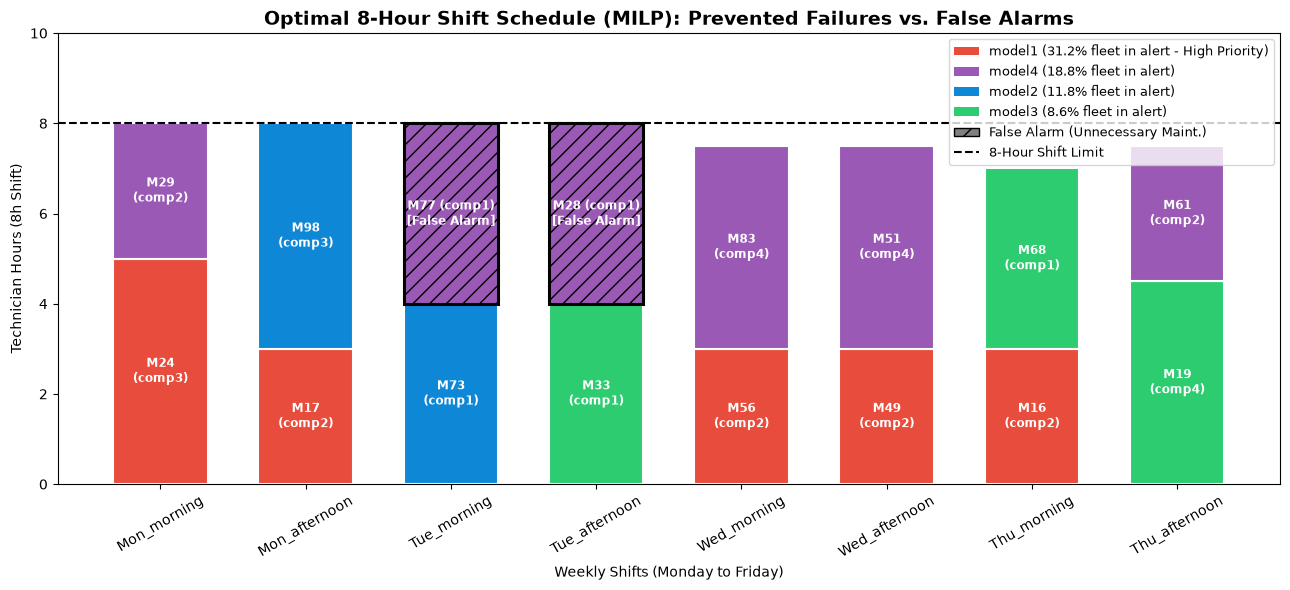

In [ ]:
fig, ax = plt.subplots(figsize=(13, 6))

model_colors = {'model1': '#e74c3c', 'model2': '#0f87d7', 'model3': '#2ecc71', 'model4': '#9b59b6'}
bottoms = np.zeros(len(shifts))

for _, row in df_schedule.iterrows():
    t = row['shift_idx']
    hrs = row['repair_hours']
    mod = row['model']
    is_false = (row['outcome'] == 'False Alarm')
    bar = ax.bar(
        shifts[t], hrs, bottom=bottoms[t],
        color=model_colors[mod],
        edgecolor='black' if is_false else 'white',
        linewidth=2.2 if is_false else 1.5,
        hatch='//' if is_false else None,
        width=0.65
    )
    label_txt = f"M{row['machineID']} ({row['pred_comp']})\n[False Alarm]" if is_false else f"M{row['machineID']}\n({row['pred_comp']})"
    ax.text(
        t, bottoms[t] + hrs / 2,
        label_txt,
        ha='center', va='center', color='white', fontweight='bold', fontsize=8.5
    )
    bottoms[t] += hrs

ax.axhline(8.0, color='black', linestyle='--', linewidth=1.5, label='Max Shift Capacity (8h workday)')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=model_colors['model1'], label='model1 (31.2% fleet in alert - High Priority)'),
    Patch(facecolor=model_colors['model4'], label='model4 (18.8% fleet in alert)'),
    Patch(facecolor=model_colors['model2'], label='model2 (11.8% fleet in alert)'),
    Patch(facecolor=model_colors['model3'], label='model3 (8.6% fleet in alert)'),
    Patch(facecolor='gray', edgecolor='black', hatch='//', label='False Alarm (Unnecessary Maint.)'),
    plt.Line2D([0], [0], color='black', linestyle='--', label='8-Hour Shift Limit')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

ax.set_ylim(0, 10.0)
ax.set_ylabel('Technician Hours (8h Shift)')
ax.set_xlabel('Weekly Shifts (Monday to Friday)')
ax.set_title('Optimal 8-Hour Shift Schedule (MILP): Prevented Failures vs. False Alarms', fontsize=14, fontweight='bold')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('../img/milp_schedule.png', dpi=300)
plt.show()
connection.close()